<a href="https://colab.research.google.com/github/abuebayyeh/imperial_eee_machine_learning_course/blob/main/06_ML_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Support Vector Machines (SVMs)


---
In the previous exercise, we used the Perceptron Learning Algorithm (PLA) for binary classification. The perceptron looks for a decision boundary that separates the two classes. For linearly separable data, however, there may be many possible decision boundaries. The figure below shows several lines that correctly separate the same two classes. Support Vector Machines (SVMs) take this idea one step further. Instead of finding any separating boundary, an SVM looks for the one that leaves the largest possible margin between the two classes. The data points closest to the decision boundary are called **support vectors**. These points determine the position of the boundary and its margin.



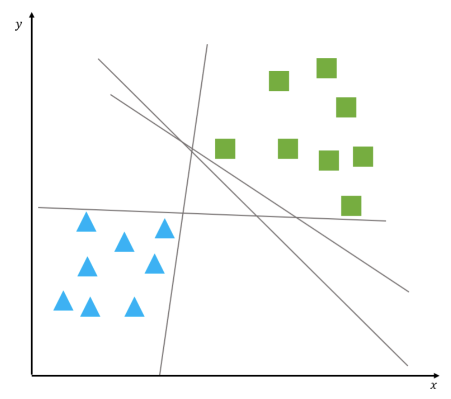



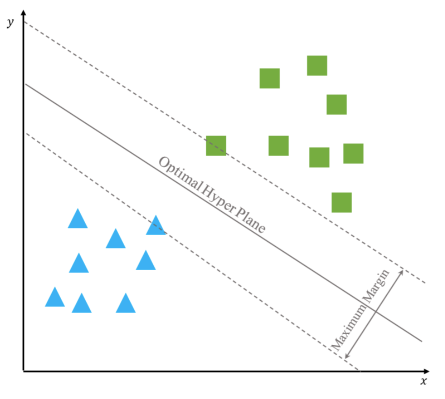


# Hard Margin SVM



## 1. Objective Function

In the context of hard-margin SVM, the aim is to determine a hyper-plane characterised by a weight vector $\mathbf{W}$ and a bias $\mathbf{b}$. The objective function is formulated as:

$$
\text{Minimise} \quad \frac{1}{2} \| \mathbf{W} \|_2^2
$$

This function represents the squared Euclidean norm of the weight vector $\mathbf{W}$, quantifying the margin.

## 2. Margin Constraints

The hard-margin SVM enforces specific constraints to guarantee accurate classification of each data point. For a dataset containing $m$ instances, these constraints are expressed as:

$$
y_i (\mathbf{X}_i \cdot \mathbf{W} + b) \geq 1 \quad \text{for } i = 1, 2, \ldots, m
$$

Here, $\mathbf{X}_i$ represents the feature vector of the *i*-th instance, and $\mathbf{y}_i$ is its associated class label (+1 or -1).

## 3. Lagrange Multipliers

Lagrange multipliers (dual variables) are introduced to transform the constrained optimisation problem into an unconstrained one. Let $\mathbf{\alpha}_i$ be the Lagrange multiplier linked to the *i*-th constraint. The Lagrangian $\mathbf{L}$ is formulated as:

$$
L(\mathbf{W}, b, \boldsymbol{\alpha}) = \frac{1}{2} \| \mathbf{W} \|_2^2 + \sum_{i=1}^m \alpha_i \left( 1 - y_i (\mathbf{X}_i \cdot \mathbf{W} + b) \right)
$$

The dual problem involves maximizing the Lagrangian with respect to the Lagrange multipliers $\mathbf{\alpha}_i$:

$$
\text{Maximise} \quad L(\mathbf{W}, b, \boldsymbol{\alpha})
$$

Subject to the constraint $\mathbf{\alpha}_i$ ≥ 0 for all *i* (since the Lagrange multipliers are non-negative).

## 4. Solving the Dual Problem

The dual problem is a maximization problem involving the Lagrangian. To solve it, we compute the derivative of $\mathbf{L}$ with respect to $\mathbf{W}$ and $\mathbf{b}$, set these derivatives to zero, and substitute the results back into the Lagrangian. This process leads to a dual optimisation problem involving only the Lagrange multipliers $\mathbf{\alpha}_i$.

Solving the dual problem yields the optimal values of $\mathbf{\alpha}$. The instances corresponding to non-zero $\mathbf{\alpha}_i$ values are the support vectors. The decision boundary is expressed using the support vectors and the Lagrange multipliers.

## 5. Constructing the Decision Boundary

Once the optimal Lagrange multipliers $\mathbf{\alpha}$ are obtained, the decision boundary can be constructed using the support vectors. The weight vector $\mathbf{W}^*$ is computed as a linear combination of the support vectors:

$$
\mathbf{W}^* = \sum_{i=1}^m \alpha_i y_i \mathbf{X}_i
$$

The bias $\mathbf{b}$ can be determined using:

$$
b = \frac{1}{y_i} - \mathbf{X}_i \cdot \mathbf{W}^*
$$


In summary, the hard-margin SVM involves formulating the SVM problem with an objective function and margin constraints, introducing Lagrange multipliers to transform the problem, solving the dual optimisation problem, and then using the obtained Lagrange multipliers to construct the decision boundary and make predictions.

The provided code aligns with this theoretical framework by formulating the SVM optimisation problem, solving it using `cvxpy`, and visualising the results. More information about using the library `cvxpy` can be found [here](https://www.cvxpy.org/)

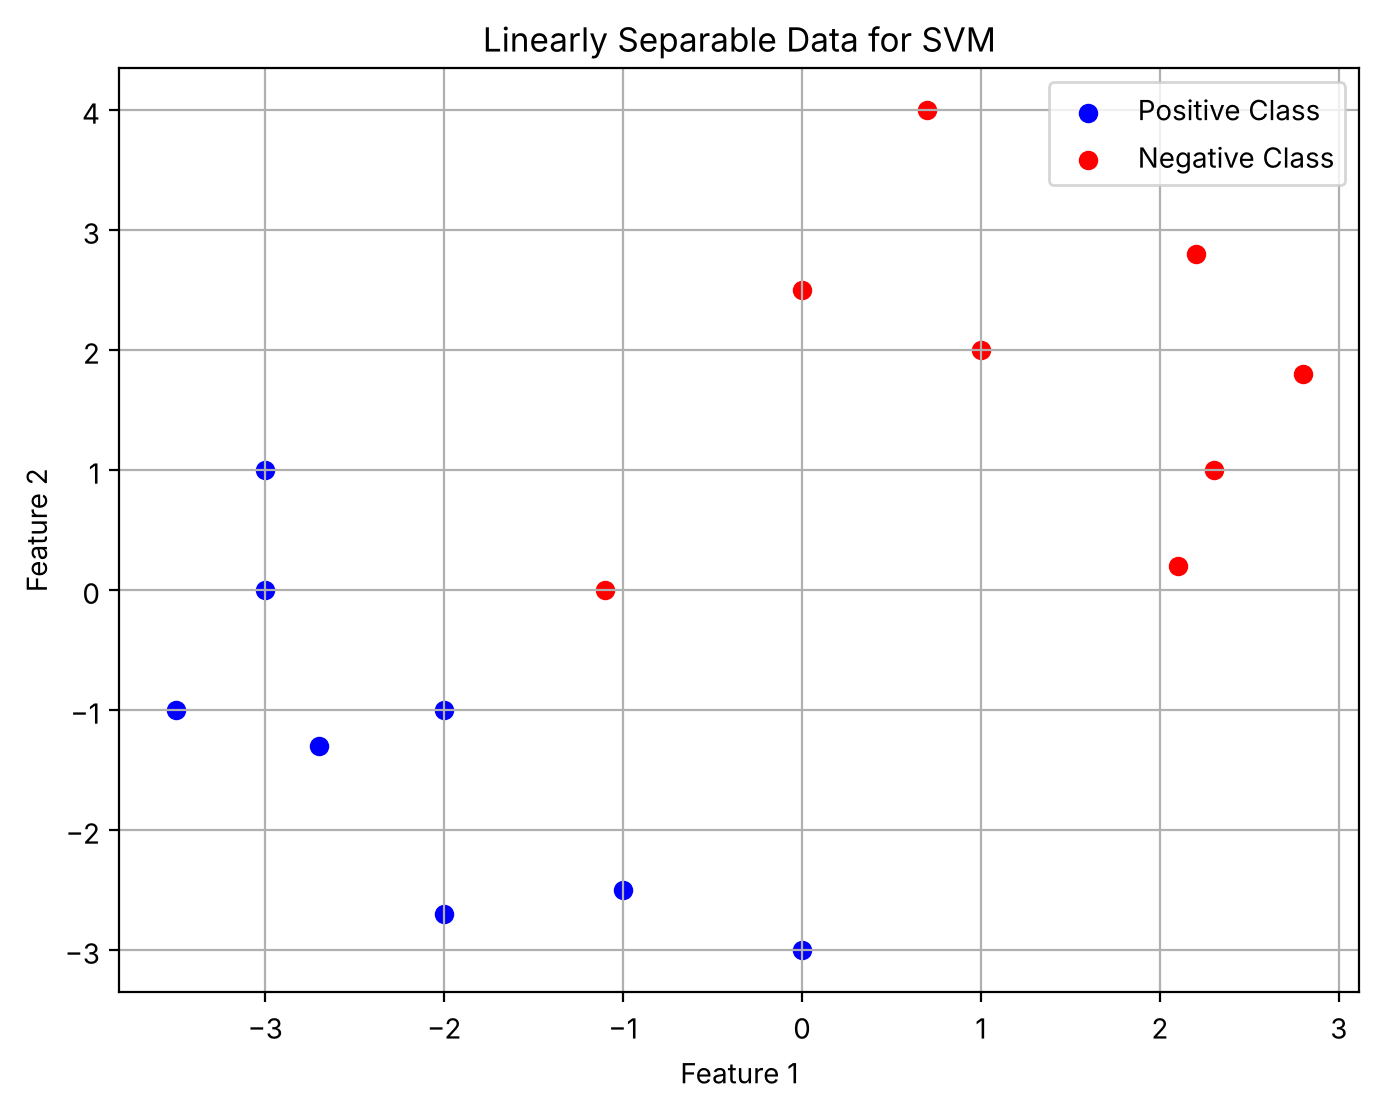

In [1]:
# Create linearly separable data

import numpy as np
import matplotlib.pyplot as plt

# Generate positive class samples
X_positive = np.array([[-3.5, -1], [-3, 0], [-3, 1], [-2.7, -1.3], [-2, -1], [-2, -2.7],
                       [-1, -2.5], [0, -3]])
y_positive = np.ones(len(X_positive))

# Generate negative class samples
X_negative = np.array([[-1.1, 0], [0, 2.5], [1, 2], [0.7, 4],
                       [2.1, 0.2], [2.3, 1], [2.8, 1.8], [2.2, 2.8]])
y_negative = -np.ones(len(X_negative))

# Concatenate positive and negative samples
X = np.vstack((X_positive, X_negative))
y = np.concatenate((y_positive, y_negative))

# Plotting
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], marker='o', label='Positive Class', color='blue')
plt.scatter(X[y == -1][:, 0], X[y == -1][:, 1], marker='o', label='Negative Class', color='red')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Linearly Separable Data for SVM')
plt.legend()
plt.grid()
plt.show()

In [2]:
import cvxpy as cp


def hard_margin(X, y):
    m, n = X.shape

    # Define the SVM optimization problem
    W = cp.Variable(n, value=np.zeros(n))  # Weights
    b = cp.Variable(value=0)               # Bias
    objective = cp.Minimize(0.5 * cp.square(cp.norm(W)))
    constraints = [y[i] * (X[i] @ W + b)  >= 1 for i in range(m)]  # Margin constraints

    # Formulate and solve the SVM problem
    prob = cp.Problem(objective, constraints)
    prob.solve()

    # Check if the problem was solved successfully
    if prob.status != cp.OPTIMAL:
        print("SVM optimization failed. Please check the data and constraints.")
        return

    # Get the optimal values of W and b
    W_optimal = W.value
    b_optimal = b.value
    print("Optimal value of W:", W_optimal)
    print("Optimal value of b:", b_optimal)

    # Calculate the slope and intercept of the decision boundary
    slope = -W_optimal[0] / W_optimal[1]
    intercept = -b_optimal / W_optimal[1]

    # Calculate the support vectors
    alphas = np.array([constraints[i].dual_value for i in range(m)])  # Extract alphas corresponding to support vectors
    non_zero_alphas = alphas[np.where(alphas > 1e-4)] # Due to approximations you may get too small values for alpha instead of zero. We will consider values below 1e-4 as zero for alpha.
    support_vectors = X[np.where(alphas > 1e-4)]  # Choose support vectors with non-zero dual values
    #print(alphas)
    print("Non_zero aplhas:", non_zero_alphas)
    print("Support Vectors:\n", support_vectors)


    # Plot the data points and decision boundary
    #plt.figure(figsize=(8, 6))
    plt.scatter(X[:, 0], X[:, 1], c=y)
    x_vals = np.array([np.min(X[:, 0]) - 1, np.max(X[:, 0]) + 1])
    y_vals = slope * x_vals + intercept
    plt.plot(x_vals, y_vals, label='Decision Boundary', color='black')

    # Plot the support vectors
    margin = 1 / W_optimal[1]
    y_down = y_vals - margin
    y_up = y_vals + margin
    plt.plot(x_vals, y_down, linestyle='dotted', color='grey')
    plt.plot(x_vals, y_up, linestyle='dotted', color='grey')
    plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=80, facecolors='none', edgecolors='r', label='Support Vectors')

    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()
    plt.title('Hard Margin SVM Decision Boundary')
    plt.grid()
    plt.show()

Optimal value of W: [-1.73913043 -1.30434783]
Optimal value of b: -2.913043478293933
Non_zero aplhas: [1.44612493 0.91682403 2.36294896]
Support Vectors:
 [[-3.   1. ]
 [ 0.  -3. ]
 [-1.1  0. ]]


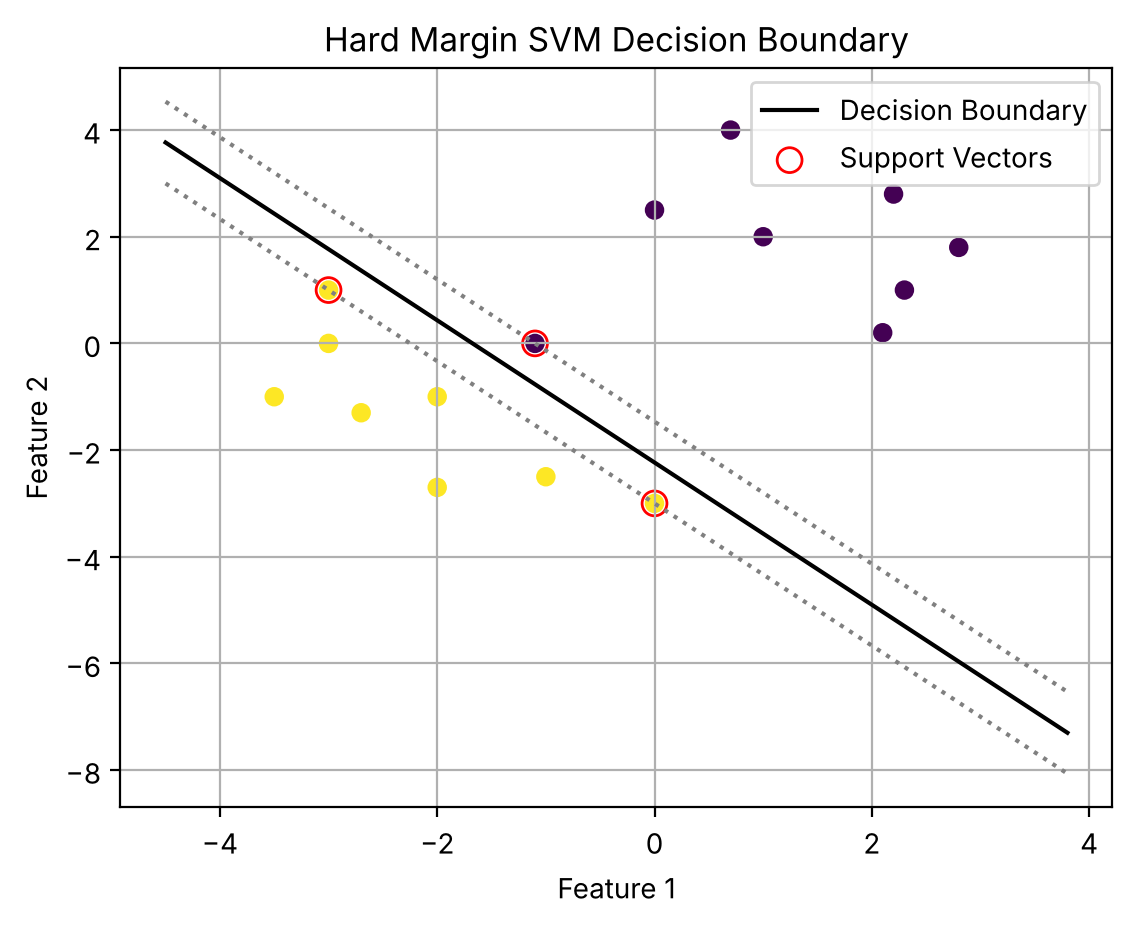

In [3]:
hard_margin(X, y)

## Task 1 [10 marks]

In this task, you will compare the outcomes calculated in **Exam Paper 2022 - Question 1** with the results obtained from the provided hard-margin SVM function when applied to the same dataset.


1. Begin by revisiting the results obtained in **Exam Paper 2022 - Question 1**. Remind yourself of the Lagrange multipliers ($\boldsymbol{\alpha}$)  calculated and the support vectors that were identified using manual calculations.

2. Next, employ the provided hard-margin SVM function to train an SVM classifier on the same dataset. The function will automatically determine the optimal parameters and pinpoint the support vectors.

3.  Create a plot that displays the dataset's data points, the decision boundary, margins, and the support vectors. This visual representation will help you comprehend how the SVM separates the classes.

4. Compare the ($\boldsymbol{\alpha}$) values calculated in **Exam Paper 2022 - Question 1** with the dual values obtained using the SVM function. Additionally, pay attention to the support vectors identified through both manual calculations and the `hard_margin` function. Comment on the similarities (and differences if any) you observe between the two sets of results.

5. Discuss your findings regarding the discrepancies and agreements between your manual calculations and the SVM function's outcomes.

6. Include the generated plot in your documentation that show the data along with the decision boundary, margins, and support vectors.




### Task 1 – Exam Paper 2022, Question 1 vs `hard_margin`

> **Fill in the next cell before running it.** The dataset and your hand-calculated Lagrange multipliers from **Exam Paper 2022 – Question 1** are not in this notebook. Copy the exam's data points into `X_exam` / `y_exam` (labels must be +1 / −1), and your manual α values into `alpha_manual`, in the same order as the points (use 0 for points that are not support vectors). Until you do, the cell runs on the tutorial dataset so the code can be checked.

>>> Exam data not entered yet - running on the tutorial dataset as a placeholder.

Optimal value of W: [-1.73913043 -1.30434783]
Optimal value of b: -2.913043478293933
Non_zero aplhas: [1.44612493 0.91682403 2.36294896]
Support Vectors:
 [[-3.   1. ]
 [ 0.  -3. ]
 [-1.1  0. ]]


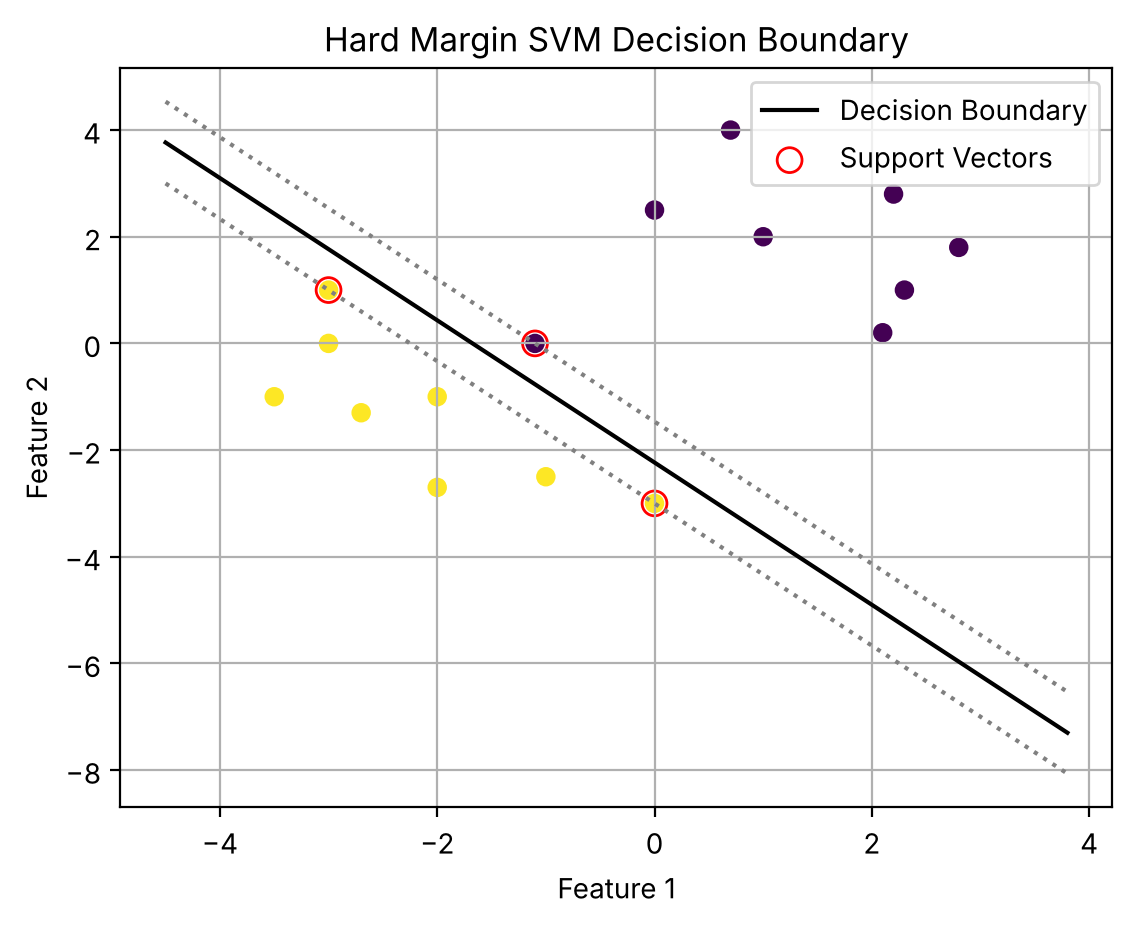

,x1,x2,y,alpha (cvxpy dual),SV (cvxpy)
0,-3.5,-1.0,1.0,0.0000,False
1,-3.0,0.0,1.0,0.0000,False
2,-3.0,1.0,1.0,1.4461,True
3,-2.7,-1.3,1.0,0.0000,False
4,-2.0,-1.0,1.0,0.0000,False
5,-2.0,-2.7,1.0,0.0000,False
6,-1.0,-2.5,1.0,0.0000,False
7,0.0,-3.0,1.0,0.9168,True
8,-1.1,0.0,-1.0,2.3629,True
9,0.0,2.5,-1.0,0.0000,False


W from optimiser:               [-1.7391 -1.3043]
W = sum(alpha_i y_i x_i):       [-1.7391 -1.3043]
sum(alpha_i y_i) (should be 0): 0.0
Margin width 2/||W||:           0.92
y_i(W.x_i + b) for the SVs (should all be 1): [1. 1. 1.]


In [4]:
# Task 1
import pandas as pd
# ===================== FILL IN FROM EXAM PAPER 2022 - QUESTION 1 =====================
X_exam = None        # e.g. np.array([[x1, x2], [x1, x2], ...])
y_exam = None        # e.g. np.array([1, 1, -1, ...])
alpha_manual = None  # e.g. np.array([a1, a2, ...])  (0 for non-support vectors)
# =====================================================================================

if X_exam is None:
    print(">>> Exam data not entered yet - running on the tutorial dataset as a placeholder.\n")
    X_t1, y_t1 = X.copy(), y.copy()
else:
    X_t1, y_t1 = np.asarray(X_exam, dtype=float), np.asarray(y_exam, dtype=float)


def hard_margin_results(X, y):
    """Same optimisation as hard_margin(), but also RETURNS W, b, all alphas and the SV mask."""
    m, n = X.shape
    W = cp.Variable(n)
    b = cp.Variable()
    constraints = [y[i] * (X[i] @ W + b) >= 1 for i in range(m)]
    prob = cp.Problem(cp.Minimize(0.5 * cp.square(cp.norm(W))), constraints)
    prob.solve()
    alphas = np.array([float(constraints[i].dual_value) for i in range(m)])
    return W.value, float(b.value), alphas, alphas > 1e-4


# Steps 2-3: train with the provided function (prints W, b, alphas, SVs and draws the plot)
hard_margin(X_t1, y_t1)

# Step 4: compare alphas and support vectors
W_t1, b_t1, alpha_cvx, sv_mask = hard_margin_results(X_t1, y_t1)
comp = pd.DataFrame({"x1": X_t1[:, 0], "x2": X_t1[:, 1], "y": y_t1,
                     "alpha (cvxpy dual)": np.round(alpha_cvx, 4),
                     "SV (cvxpy)": sv_mask})
if alpha_manual is not None:
    alpha_manual = np.asarray(alpha_manual, dtype=float)
    comp["alpha (manual)"] = alpha_manual
    comp["SV (manual)"] = alpha_manual > 1e-4
    comp["difference"] = np.round(alpha_cvx - alpha_manual, 4)
display(comp)

# Consistency checks that both solutions must satisfy (KKT conditions)
W_from_alpha = (alpha_cvx * y_t1) @ X_t1
print("W from optimiser:              ", np.round(W_t1, 4))
print("W = sum(alpha_i y_i x_i):      ", np.round(W_from_alpha, 4))
print("sum(alpha_i y_i) (should be 0):", round(float(alpha_cvx @ y_t1), 6))
print("Margin width 2/||W||:          ", round(2 / np.linalg.norm(W_t1), 4))
print("y_i(W.x_i + b) for the SVs (should all be 1):", np.round(y_t1[sv_mask] * (X_t1[sv_mask] @ W_t1 + b_t1), 4))
if alpha_manual is not None:
    W_manual = (alpha_manual * y_t1) @ X_t1
    print("\nW from MANUAL alphas:          ", np.round(W_manual, 4))
    print("Same support vectors?          ", np.array_equal(sv_mask, alpha_manual > 1e-4))
    print("Max |alpha difference|:        ", round(float(np.max(np.abs(alpha_cvx - alpha_manual))), 6))

**Task 1 – what to look for in the comparison (edit once your exam numbers are in):**
* **Support vectors.** The points with non-zero α should be the same as the ones you identified by hand: the points closest to the boundary, lying exactly on the margin lines $y_i(\mathbf W\cdot\mathbf x_i + b) = 1$.
* **α values.** cvxpy solves the problem numerically (an interior-point method), so its duals match the hand calculation only up to a small tolerance (around $10^{-6}$–$10^{-4}$). Non-support vectors come out as tiny values such as $10^{-9}$ rather than exactly 0, which is why the code treats α < $10^{-4}$ as zero.
* **Checks.** Both solutions must satisfy $\sum_i \alpha_i y_i = 0$ and $\mathbf W = \sum_i \alpha_i y_i \mathbf x_i$. If your manual W, b or margin agree with the function's but some individual α values differ, the dataset may have more than three points on the margin (a degenerate case). The α values are then **not unique**, and different, equally valid combinations give the same W and b.
* **Possible sources of disagreement.** Rounding in the hand calculation, a wrong guess of which points are support vectors (the hand method usually assumes the active set in advance), or a sign or label error.

# Soft Margin SVM

The soft margin SVM extends this adaptability by introducing a flexible approach that accommodates instances that may not adhere strictly to class boundaries.

## 1. Soft Margin SVM Objective

In the context of the soft margin SVM, the objective shifts from aiming for perfect separation to achieving a balance between maximizing the margin and allowing some instances to relax their adherence to strict classification boundaries. This equilibrium is controlled by the hyper-parameter $ C $. The objective function is designed as:

$$
\text{Minimise} \quad \frac{1}{2} \| \mathbf{W} \|_2^2 + C \sum_{i=1}^{m} \xi_i
$$

Here, $ C $ regulates the trade-off between expanding the margin and allowing instances to ease their strict classification.

## 2. Margin Constraints and Flexibility

The constraints in the soft margin SVM introduce a "relaxing corridor" for instances. This acknowledges that not all instances can be perfectly classified, and thus, non-negative slack variables $ \xi_i $ are introduced to accommodate instances that may not strictly satisfy the margin conditions. The margin constraints are expressed as:

$$
y_i (\mathbf{X}_i \cdot \mathbf{W} + b) \geq 1 - \xi_i \quad \text{for } i = 1, 2, \ldots, m
$$

These constraints allow instances to move slightly inside the margin or even on the wrong side of the decision boundary, with a penalty proportional to $ \xi_i $.

## 3. Lagrange Multipliers and Dual Problem

As in the hard-margin case, Lagrange multipliers $ \alpha_i $ are introduced to transform the optimization problem. The Lagrangian for the soft margin SVM incorporates the slack variables and is given by:

$$
L(\mathbf{W}, b, \boldsymbol{\alpha}, \boldsymbol{\xi}, \boldsymbol{\beta}) = \frac{1}{2} \| \mathbf{W} \|_2^2 + C \sum_{i=1}^{m} \xi_i + \sum_{i=1}^{m} \alpha_i \left(1 - \xi_i - y_i (\mathbf{X}_i \cdot \mathbf{W} + b)\right) - \sum_{i=1}^{m} \beta_i \xi_i
$$

The dual problem remains focused on maximizing the Lagrangian subject to the constraint $ \alpha_i \geq 0 $.

## 4. Solving the Dual Problem

Solving the dual problem involves finding optimal Lagrange multipliers $ \alpha_i $ and slack variables $ \xi_i $ that adhere to the Karush-Kuhn-Tucker (KKT) conditions. The instances corresponding to non-zero $ \alpha_i $ values are the support vectors that actively influence the decision boundary.

## 5. Constructing the Decision Boundary

Once optimal Lagrange multipliers $ \alpha_i $ are determined, the construction of the decision boundary remains similar to the hard-margin SVM. The weight vector $ \mathbf{W}^* $ is calculated using the support vectors:

$$
\mathbf{W}^* = \sum_{i=1}^{m} \alpha_i y_i \mathbf{X}_i
$$

The bias $\mathbf{b}$ can be determined using:

$$
b = \frac{1}{y_i} - \mathbf{X}_i \cdot \mathbf{W}^*
$$

In conclusion, the soft margin SVM introduces a balanced approach, allowing instances some flexibility in adhering to strict classification boundaries. The hyper-parameter $ C $ guides this balance, offering adaptability to real-world scenarios.

## Task 2 [60 marks]

In this task, you will modify the provided hard-margin SVM code to implement a soft-margin SVM. Additionally, you will explore the impact of different values of the regularization parameter `C` on the results.

1. Use the same dataset form the first code cell.

2. Take the hard-margin SVM code provided and modify it to implement a soft-margin SVM. The new function can be named `soft_margin` and will accept `(X,y,C)` as inputs to the function.

3. Use a range of `C` values: `[1e-3, 1e-1, 1, 1e2, 1e5]`. For each value of `C`, train the soft-margin SVM on the same dataset and observe the results.

4. For each value of `C`, compare and analyze the following aspects:
   - The decision boundary and the positions of the support vectors.
   - The number of support vectors.
   - The impact on the margin width.

5. Create a summary report that includes the modified code, the results obtained for each `C` value (optimal $\mathbf{W}$ and $\mathbf{b}$ values and a plot that shows data along with margins and support vectors ), and your observations and analysis. Discuss how changing the value of `C` affects the trade-off between achieving a wider margin and allowing some misclassifications.

6. Based on your observations and analysis, conclude which values of `C` appear to work best for the given dataset and explain your reasoning.


C = 0.001
  Optimal W: [-0.0272 -0.0248] | Optimal b: -0.0098
  Support vectors: 16  (on margin: 0, alpha = C: 16)
  Margin width 2/||W|| = 54.3350 | sum(xi) = 14.6451 | misclassified = 1


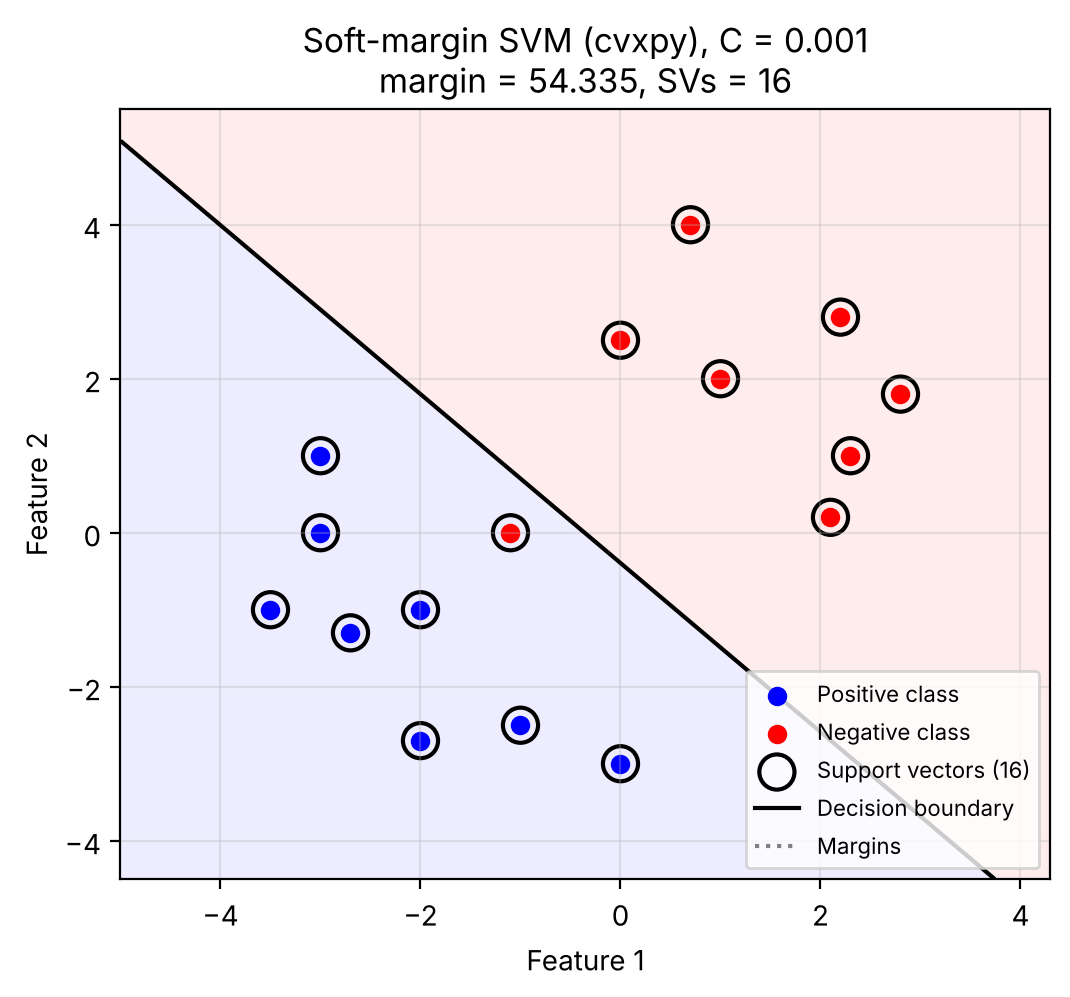

C = 0.1
  Optimal W: [-0.3849 -0.3515] | Optimal b: -0.1213
  Support vectors: 6  (on margin: 3, alpha = C: 3)
  Margin width 2/||W|| = 3.8369 | sum(xi) = 1.6870 | misclassified = 1


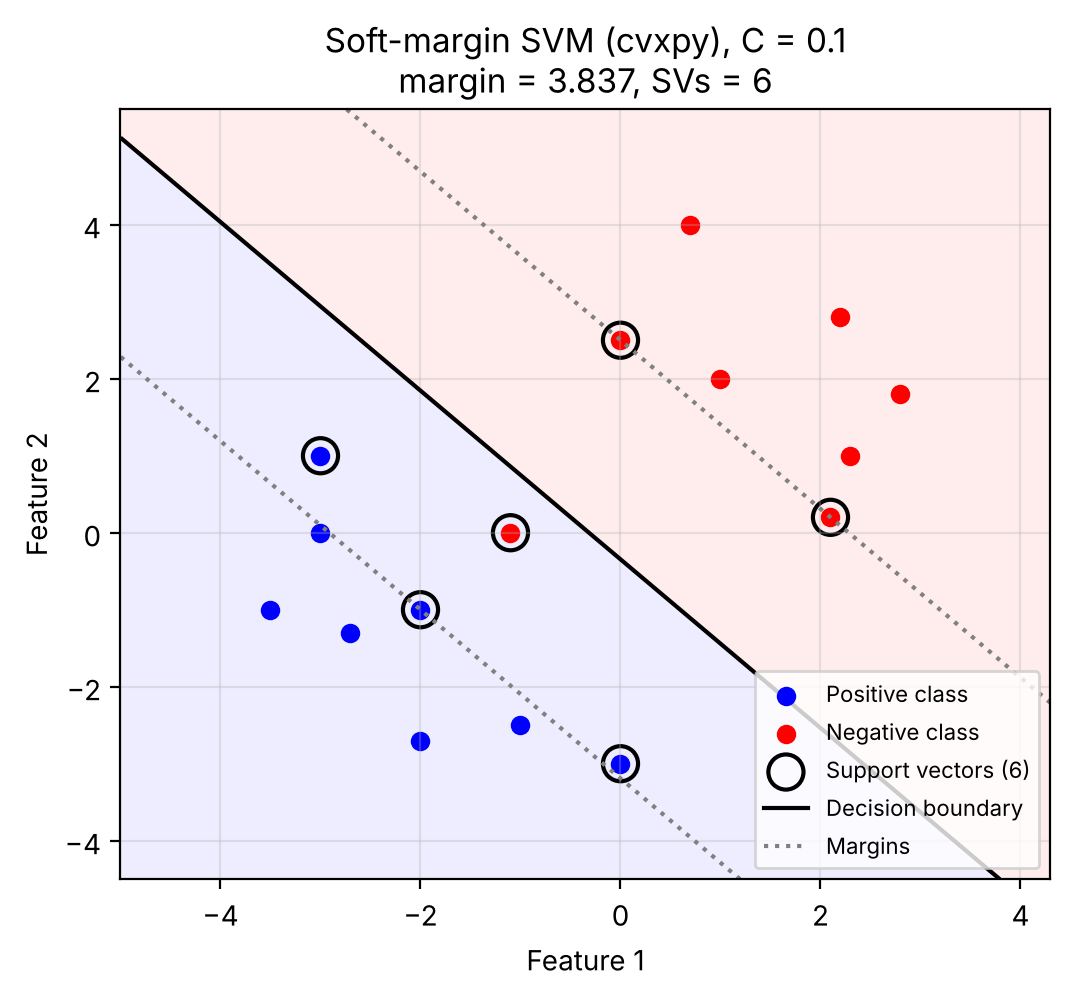

C = 1
  Optimal W: [-0.736 -0.552] | Optimal b: -0.656
  Support vectors: 3  (on margin: 2, alpha = C: 1)
  Margin width 2/||W|| = 2.1739 | sum(xi) = 1.1536 | misclassified = 1


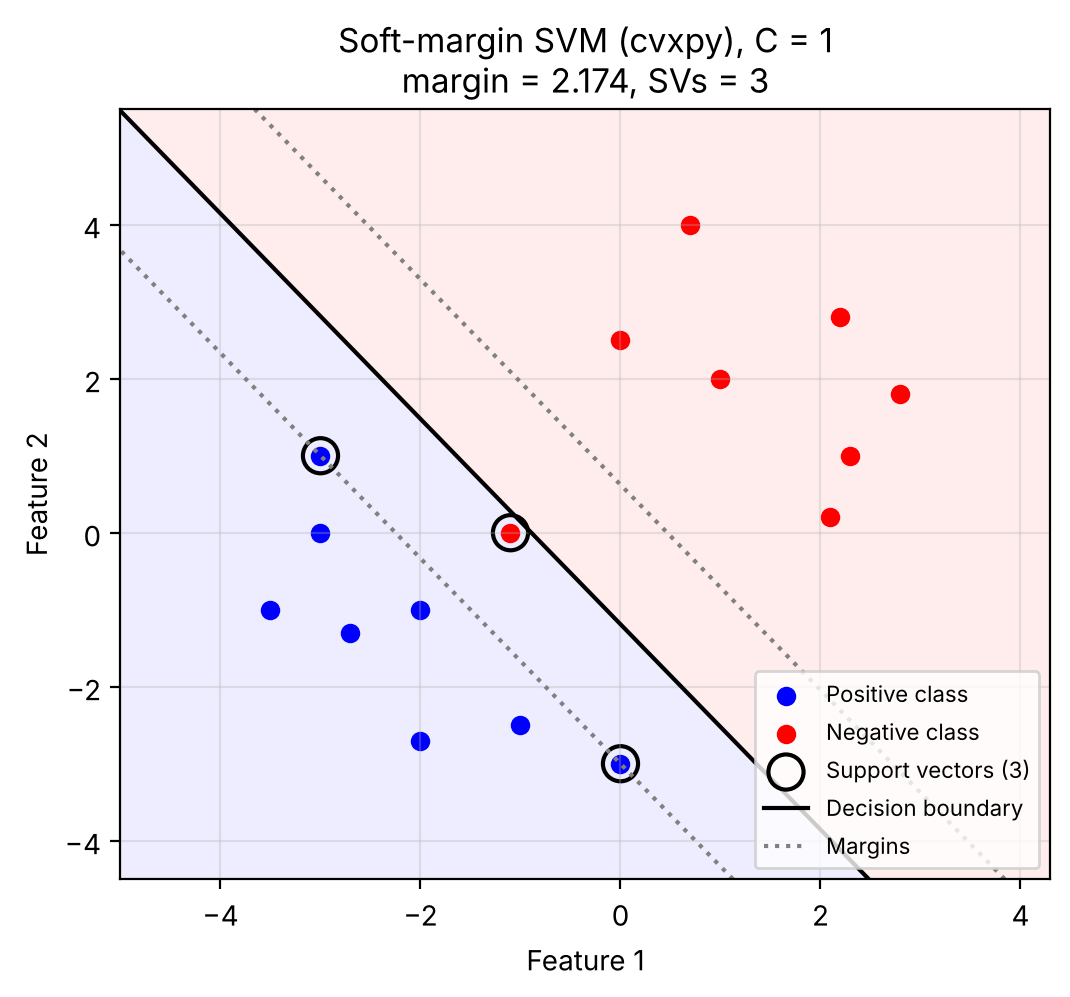

C = 100
  Optimal W: [-1.7391 -1.3043] | Optimal b: -2.913
  Support vectors: 3  (on margin: 3, alpha = C: 0)
  Margin width 2/||W|| = 0.9200 | sum(xi) = 0.0000 | misclassified = 0


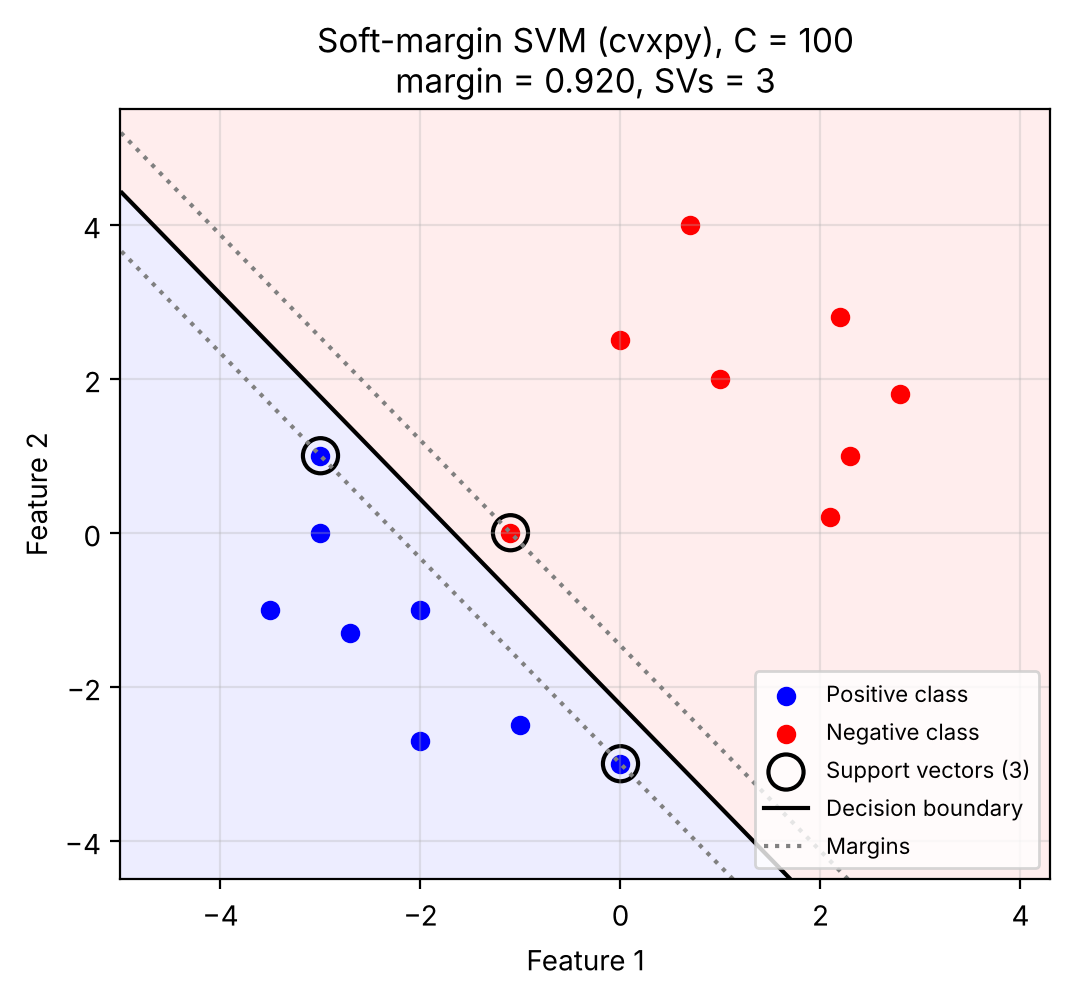

C = 100000
  Optimal W: [-1.7391 -1.3043] | Optimal b: -2.913
  Support vectors: 3  (on margin: 3, alpha = C: 0)
  Margin width 2/||W|| = 0.9200 | sum(xi) = 0.0000 | misclassified = 0


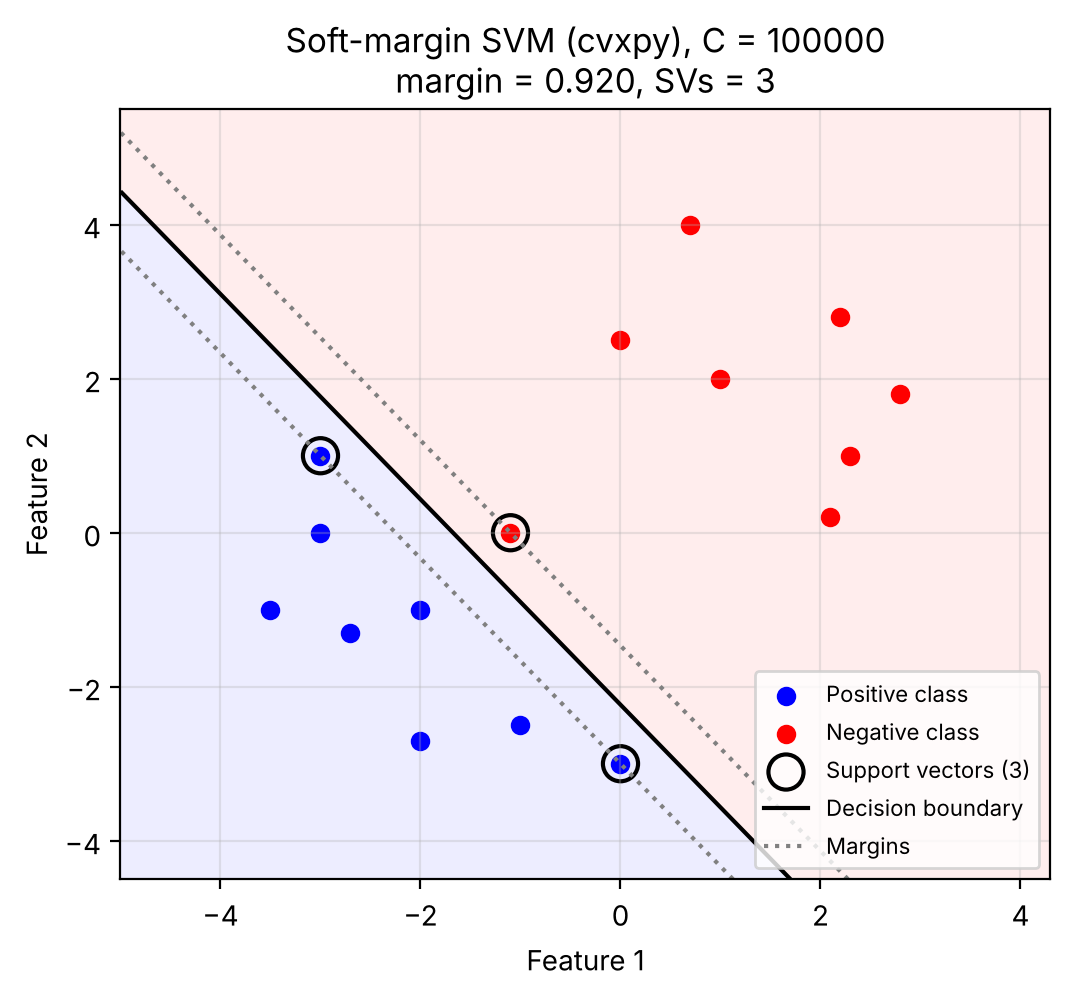

,C,W,b,n_SV,SV on margin,SV with alpha=C,margin width,sum xi,misclassified
0,0.001,"[-0.0272, -0.0248]",-0.0098,16,0,16,54.3350,14.6451,1
1,0.100,"[-0.3849, -0.3515]",-0.1213,6,3,3,3.8369,1.6870,1
2,1.000,"[-0.736, -0.552]",-0.6560,3,2,1,2.1739,1.1536,1
3,100.000,"[-1.7391, -1.3043]",-2.9130,3,3,0,0.9200,0.0000,0
4,100000.000,"[-1.7391, -1.3043]",-2.9130,3,3,0,0.9200,0.0000,0


In [5]:
# Task 2
# Soft-margin SVM: the hard-margin code with three changes
#   1) slack variables xi_i >= 0 are added
#   2) constraints become  y_i (W.x_i + b) >= 1 - xi_i
#   3) objective becomes   0.5 ||W||^2 + C * sum(xi_i)
# Support vectors are points with alpha_i > 0. For soft margin, 0 < alpha_i < C means the point is ON
# the margin, and alpha_i = C means it is inside the margin or misclassified (xi_i > 0).

def plot_svm(X, y, W, b, sv, title):
    """Data, decision boundary (W.x+b=0), margins (W.x+b=+-1) and support vectors.
    Drawn with contours of W.x+b so it works for any W (no division by W[1])."""
    pad = 1.5
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
    f = W[0] * xx + W[1] * yy + b
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, f, levels=[-1e9, 0, 1e9], colors=['#ffdddd', '#ddddff'], alpha=0.5)
    cs = plt.contour(xx, yy, f, levels=[-1, 0, 1], colors=['grey', 'black', 'grey'],
                     linestyles=['dotted', 'solid', 'dotted'])
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Positive class')
    plt.scatter(X[y == -1, 0], X[y == -1, 1], color='red', label='Negative class')
    plt.scatter(X[sv, 0], X[sv, 1], s=160, facecolors='none', edgecolors='k', linewidths=1.5,
                label=f'Support vectors ({sv.sum()})')
    plt.plot([], [], 'k-', label='Decision boundary'); plt.plot([], [], color='grey', linestyle='dotted', label='Margins')
    plt.xlim(x_min, x_max); plt.ylim(y_min, y_max)
    plt.xlabel('Feature 1'); plt.ylabel('Feature 2'); plt.title(title)
    plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=0.3); plt.show()


def soft_margin(X, y, C):
    m, n = X.shape
    W = cp.Variable(n)                         # weights
    b = cp.Variable()                          # bias
    xi = cp.Variable(m)                        # slack variables (new)
    objective = cp.Minimize(0.5 * cp.square(cp.norm(W)) + C * cp.sum(xi))
    constraints = [y[i] * (X[i] @ W + b) >= 1 - xi[i] for i in range(m)]   # relaxed margin constraints
    constraints += [xi >= 0]                                                  # slack must be non-negative
    prob = cp.Problem(objective, constraints)
    prob.solve(solver=cp.CLARABEL)            # Clarabel stays accurate even for very large C

    if prob.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        print("SVM optimization failed:", prob.status)
        return None

    W_opt, b_opt, xi_opt = W.value, float(b.value), np.maximum(xi.value, 0)
    alphas = np.array([float(constraints[i].dual_value) for i in range(m)])
    sv = alphas > 1e-4
    margin_width = 2 / np.linalg.norm(W_opt)
    n_misclassified = int(np.sum(np.sign(X @ W_opt + b_opt) != y))
    on_margin = sv & (alphas < C * (1 - 1e-3))     # 0 < alpha < C
    bounded = sv & ~on_margin                       # alpha = C  (inside margin / wrong side)

    print(f"C = {C:g}")
    print("  Optimal W:", np.round(W_opt, 4), "| Optimal b:", round(b_opt, 4))
    print(f"  Support vectors: {sv.sum()}  (on margin: {on_margin.sum()}, alpha = C: {bounded.sum()})")
    print(f"  Margin width 2/||W|| = {margin_width:.4f} | sum(xi) = {xi_opt.sum():.4f} | misclassified = {n_misclassified}")
    plot_svm(X, y, W_opt, b_opt, sv, f"Soft-margin SVM (cvxpy), C = {C:g}\nmargin = {margin_width:.3f}, SVs = {sv.sum()}")
    return {"C": C, "W": np.round(W_opt, 4), "b": round(b_opt, 4), "n_SV": int(sv.sum()),
            "SV on margin": int(on_margin.sum()), "SV with alpha=C": int(bounded.sum()),
            "margin width": round(margin_width, 4), "sum xi": round(xi_opt.sum(), 4),
            "misclassified": n_misclassified}


C_values = [1e-3, 1e-1, 1, 1e2, 1e5]
soft_results = [soft_margin(X, y, c) for c in C_values]

import pandas as pd
soft_df = pd.DataFrame(soft_results)
soft_df

**Task 2 – observations and analysis**

The objective $\tfrac12\|\mathbf W\|^2 + C\sum\xi_i$ trades a **wide margin** (small $\|\mathbf W\|$) against **margin violations** (slack $\xi_i$). $C$ sets the price of each violation.

| C | Behaviour |
|---|---|
| **10⁻³** | Violations are almost free, so the optimiser makes $\|\mathbf W\|$ tiny. The margin becomes enormous (≈ 54, wider than the whole dataset) and **all 16 points are support vectors**, all with α = C. The boundary is set by the overall class averages, not by the nearest points, and one point is on the wrong side. This **underfits**. |
| **0.1** | The margin shrinks to about 3.8 with 6 support vectors, still mostly inside the margin. |
| **1** | Margin about 2.2, 3 support vectors. The negative point (−1.1, 0), which sits right next to the positive class, is still **allowed to be misclassified** in exchange for a wider margin. |
| **100** and **10⁵** | Violations are now so expensive that the solution is the **hard-margin SVM**: W ≈ (−1.739, −1.304), b ≈ −2.913, margin ≈ 0.92, no misclassifications. There are exactly 3 support vectors, all lying on the margin lines: (−3, 1), (0, −3) and (−1.1, 0). Raising C beyond the point where all slacks are 0 changes nothing. |

* **Decision boundary and support vectors.** Small C: the boundary is pulled towards the middle of the two clouds, and many points become support vectors because they lie inside the wide margin. As C grows, the support vectors reduce to the few points that are hardest to separate, and the boundary tilts to separate (−1.1, 0) correctly.
* **Number of support vectors** falls as C increases (16 → 6 → 3 → 3 → 3).
* **Margin width** falls as C increases (≈ 54 → 3.8 → 2.2 → 0.92 → 0.92).

**Which C is best?** This dataset is linearly separable, so **C ≥ 100** gives the maximum-margin separator with zero training errors, and it is the only setting that classifies (−1.1, 0) correctly. However, that point is very close to the positive class, so it squeezes the margin down to 0.92. If it were treated as a possible outlier or label noise, **C = 1** would be a reasonable compromise: a margin more than twice as wide, at the cost of one training error, and probably more robust on new data. Without a validation set, I would pick **C = 100** for this data (exact separation, same as hard margin), and C ≈ 1 if robustness to noise matters more.

# Scikit-learn Implementation

Scikit-learn provides a convenient and user-friendly way to do so. First, you'll need to import the necessary module:
```python
from sklearn.svm import SVC
```

You can initialise the classifier with various parameters:
> More information can be found [here](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC)



## Task 3 [30 marks]



In this task, you will implement both the soft-margin and hard-margin Support Vector Machine (SVM) representations using the scikit-learn library for the same dataset. You will document your code, generate plots to visualise the decision boundaries, margins, and support vectors, and extract the optimal values of ($\mathbf{W}$) and $\mathbf{b}$.


1.  Use the same dataset form the first code cell.

2.  Using the scikit-learn library, implement the soft-margin SVM. Utilise a loop to train SVM classifiers with varying values as in Task 2. For each \( C \) value, document the optimal ($\mathbf{W}$) and $\mathbf{b}$ values obtained from the SVM model.

3. Generate plots for each \( C \) value to visualise the dataset, decision boundary, margins, and support vectors.

4.  Repeat the process for the hard-margin SVM. Train SVM classifiers using the scikit-learn library. Document the optimal \($\mathbf{W}$) and $\mathbf{b}$ value for each case.

5. Create plot similar to the soft-margin SVM case to visualise the hard-margin SVM result.

6.  Document your code, including how you loaded the data, implemented the SVM classifiers, and extracted the optimal parameters. Embed the generated plots in your documentation.

7.  Summarise your observations on the differences between soft-margin and hard-margin SVM implementation form scikitlearn perspective.



Soft-margin SVM, C = 0.001: W = [-0.0272 -0.0248], b = 0.0040, SVs = 16, margin = 54.3350, misclassified = 1
   support vectors: [[-1.1, 0.0], [0.0, 2.5], [1.0, 2.0], [0.7, 4.0], [2.1, 0.2], [2.3, 1.0], [2.8, 1.8], [2.2, 2.8], [-3.5, -1.0], [-3.0, 0.0], [-3.0, 1.0], [-2.7, -1.3], [-2.0, -1.0], [-2.0, -2.7], [-1.0, -2.5], [0.0, -3.0]] | alphas: [0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001 0.001
 0.001 0.001 0.001 0.001]


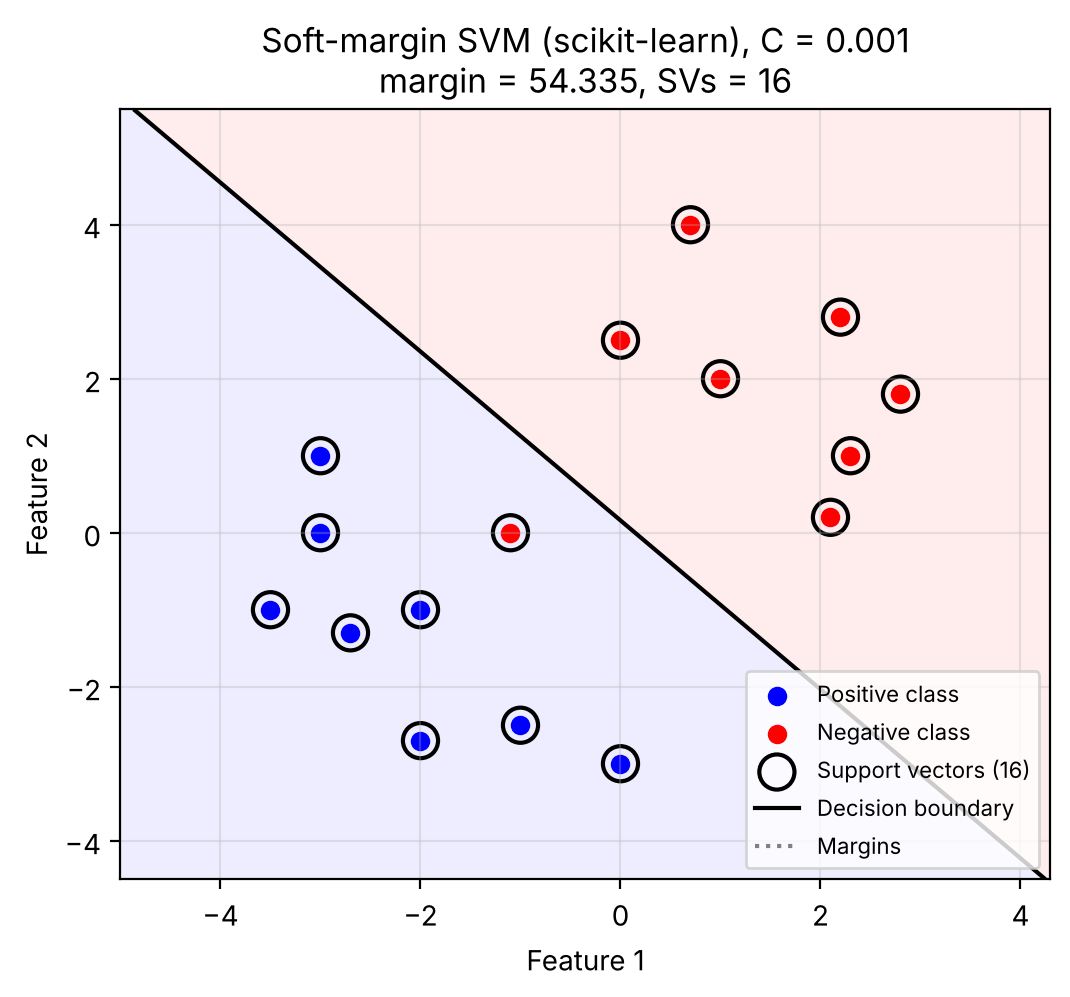

Soft-margin SVM, C = 0.1: W = [-0.3848 -0.3513], b = -0.1214, SVs = 6, margin = 3.8386, misclassified = 1
   support vectors: [[-1.1, 0.0], [0.0, 2.5], [2.1, 0.2], [-3.0, 1.0], [-2.0, -1.0], [0.0, -3.0]] | alphas: [0.1    0.0466 0.0736 0.1    0.0201 0.1   ]


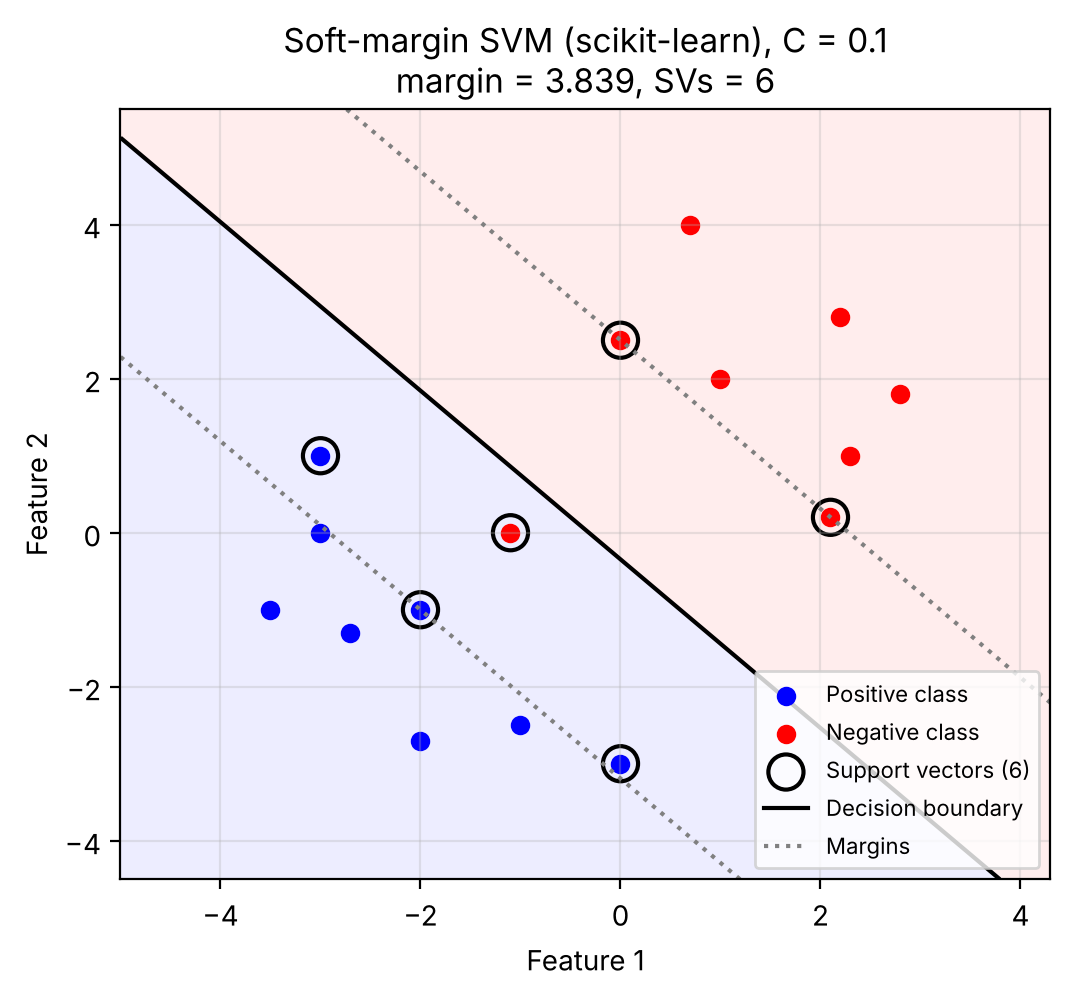

Soft-margin SVM, C = 1: W = [-0.736 -0.552], b = -0.6560, SVs = 3, margin = 2.1739, misclassified = 1
   support vectors: [[-1.1, 0.0], [-3.0, 1.0], [0.0, -3.0]] | alphas: [1.    0.612 0.388]


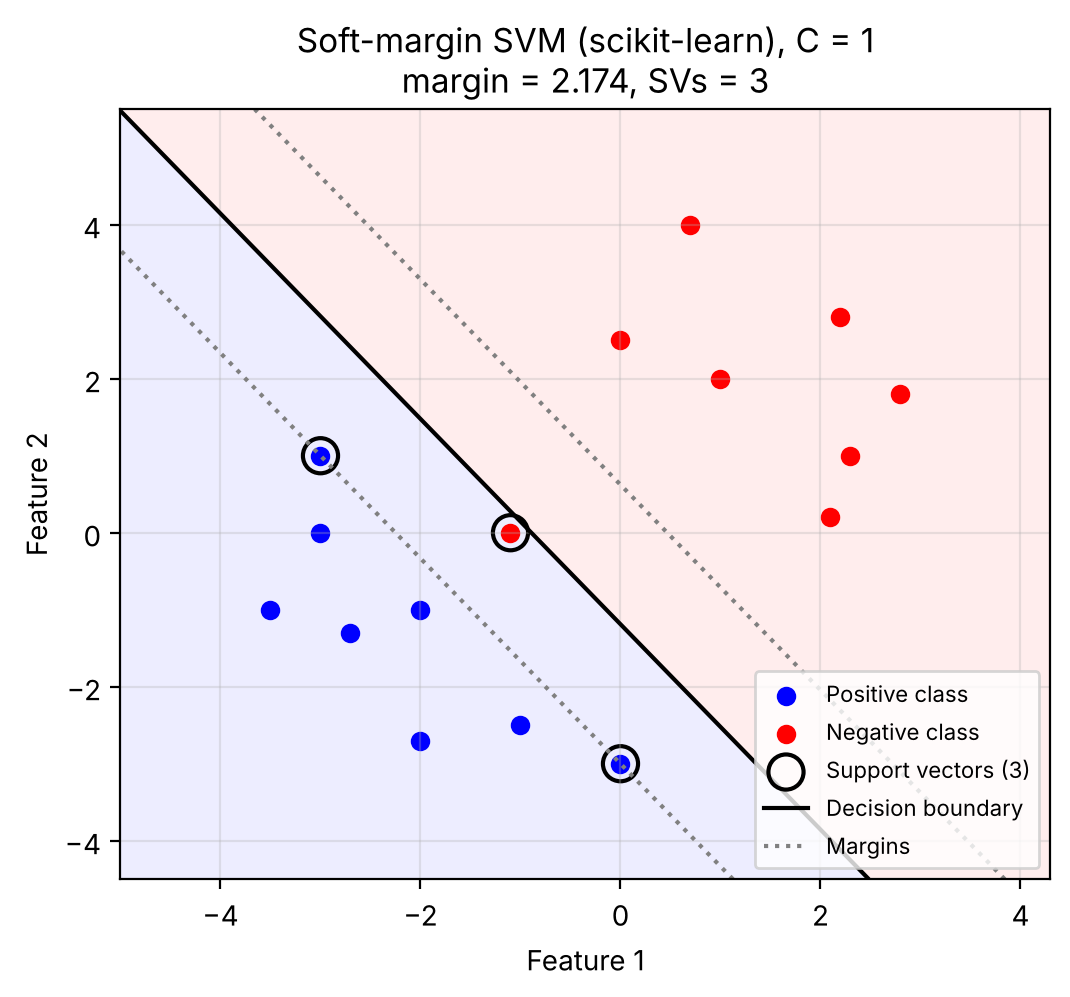

Soft-margin SVM, C = 100: W = [-1.7384 -1.3038], b = -2.9117, SVs = 3, margin = 0.9204, misclassified = 0
   support vectors: [[-1.1, 0.0], [-3.0, 1.0], [0.0, -3.0]] | alphas: [2.3619 1.4455 0.9164]


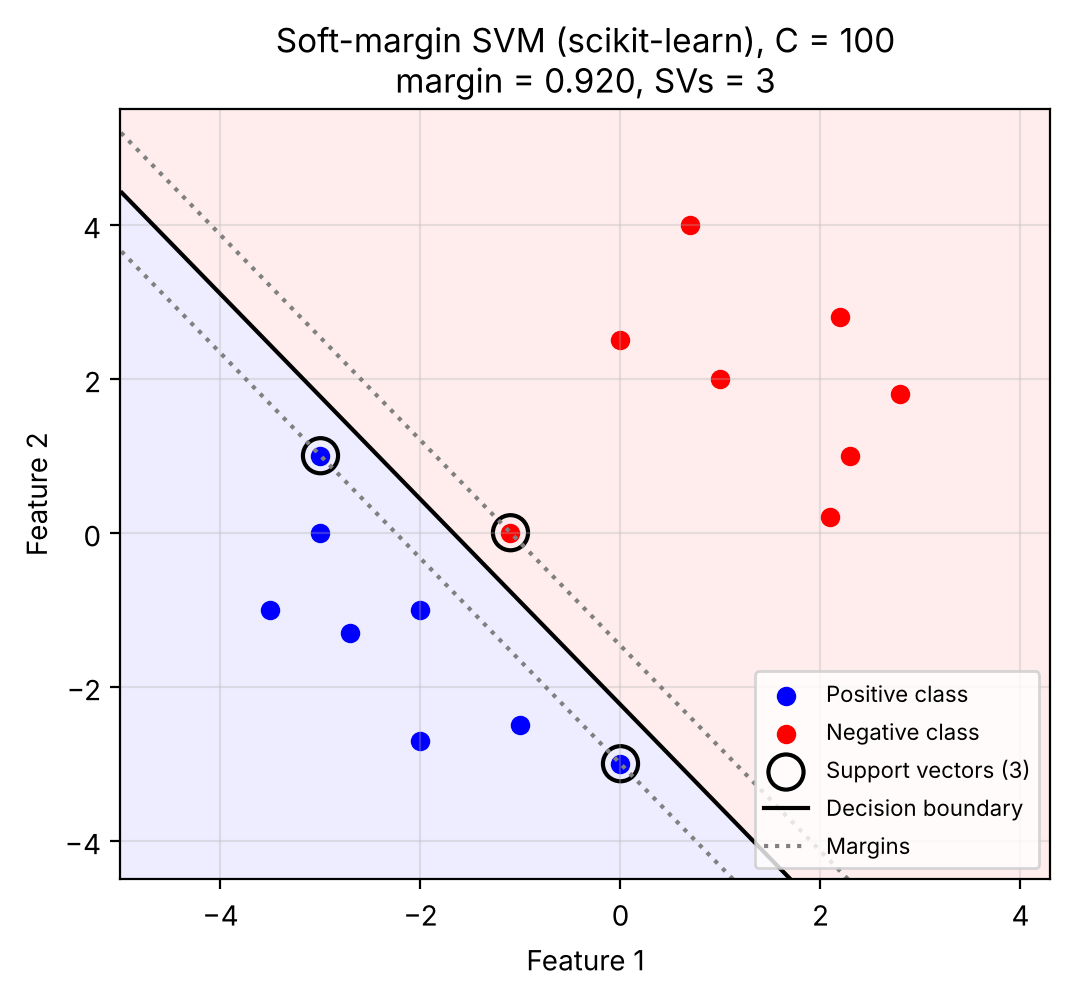

Soft-margin SVM, C = 100000: W = [-1.7384 -1.3038], b = -2.9117, SVs = 3, margin = 0.9204, misclassified = 0
   support vectors: [[-1.1, 0.0], [-3.0, 1.0], [0.0, -3.0]] | alphas: [2.3619 1.4455 0.9164]


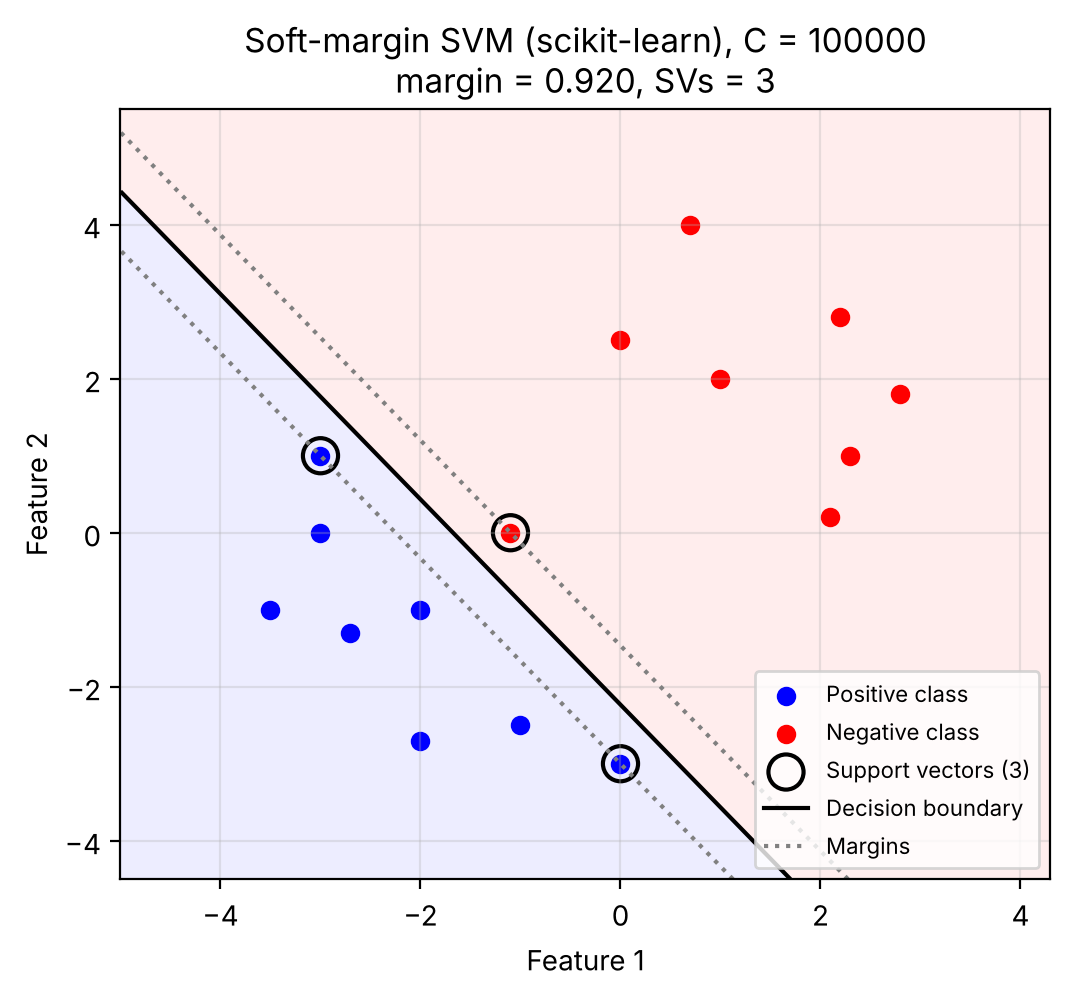

,C,W (sklearn),b (sklearn),n_SV (sklearn),margin width (sklearn),W (cvxpy),b (cvxpy),n_SV (cvxpy),margin width (cvxpy)
0,0.001,"[-0.0272, -0.0248]",0.0040,16,54.3350,"[-0.0272, -0.0248]",-0.0098,16,54.3350
1,0.100,"[-0.3848, -0.3513]",-0.1214,6,3.8386,"[-0.3849, -0.3515]",-0.1213,6,3.8369
2,1.000,"[-0.736, -0.552]",-0.6560,3,2.1739,"[-0.736, -0.552]",-0.6560,3,2.1739
3,100.000,"[-1.7384, -1.3038]",-2.9117,3,0.9204,"[-1.7391, -1.3043]",-2.9130,3,0.9200
4,100000.000,"[-1.7384, -1.3038]",-2.9117,3,0.9204,"[-1.7391, -1.3043]",-2.9130,3,0.9200


In [6]:
# Task 3 (soft margin)
# Data: the same X, y defined in the first code cell.
# SVC(kernel='linear') solves the same soft-margin problem as Task 2. After fitting:
#   coef_[0] -> W,  intercept_[0] -> b,  support_vectors_ / support_ -> the SVs,
#   dual_coef_ -> alpha_i * y_i for each SV.
from sklearn.svm import SVC

def sklearn_svm(X, y, C, title_prefix):
    clf = SVC(kernel='linear', C=C)
    clf.fit(X, y)
    W_sk = clf.coef_[0]
    b_sk = clf.intercept_[0]
    sv = np.zeros(len(X), dtype=bool); sv[clf.support_] = True
    alphas = np.abs(clf.dual_coef_[0])
    margin_width = 2 / np.linalg.norm(W_sk)
    n_mis = int(np.sum(clf.predict(X) != y))
    print(f"{title_prefix}, C = {C:g}: W = {np.round(W_sk, 4)}, b = {b_sk:.4f}, SVs = {sv.sum()}, "
          f"margin = {margin_width:.4f}, misclassified = {n_mis}")
    print("   support vectors:", clf.support_vectors_.tolist(), "| alphas:", np.round(alphas, 4))
    plot_svm(X, y, W_sk, b_sk, sv, f"{title_prefix} (scikit-learn), C = {C:g}\nmargin = {margin_width:.3f}, SVs = {sv.sum()}")
    return {"C": C, "W": np.round(W_sk, 4), "b": round(b_sk, 4), "n_SV": int(sv.sum()),
            "margin width": round(margin_width, 4), "misclassified": n_mis}

sk_soft = [sklearn_svm(X, y, c, "Soft-margin SVM") for c in C_values]
sk_soft_df = pd.DataFrame(sk_soft)

# Compare with the cvxpy results from Task 2
compare = sk_soft_df[["C", "W", "b", "n_SV", "margin width"]].merge(
    soft_df[["C", "W", "b", "n_SV", "margin width"]], on="C", suffixes=(" (sklearn)", " (cvxpy)"))
compare

Hard-margin SVM, C = 1e+10: W = [-1.7384 -1.3038], b = -2.9117, SVs = 3, margin = 0.9204, misclassified = 0
   support vectors: [[-1.1, 0.0], [-3.0, 1.0], [0.0, -3.0]] | alphas: [2.3619 1.4455 0.9164]


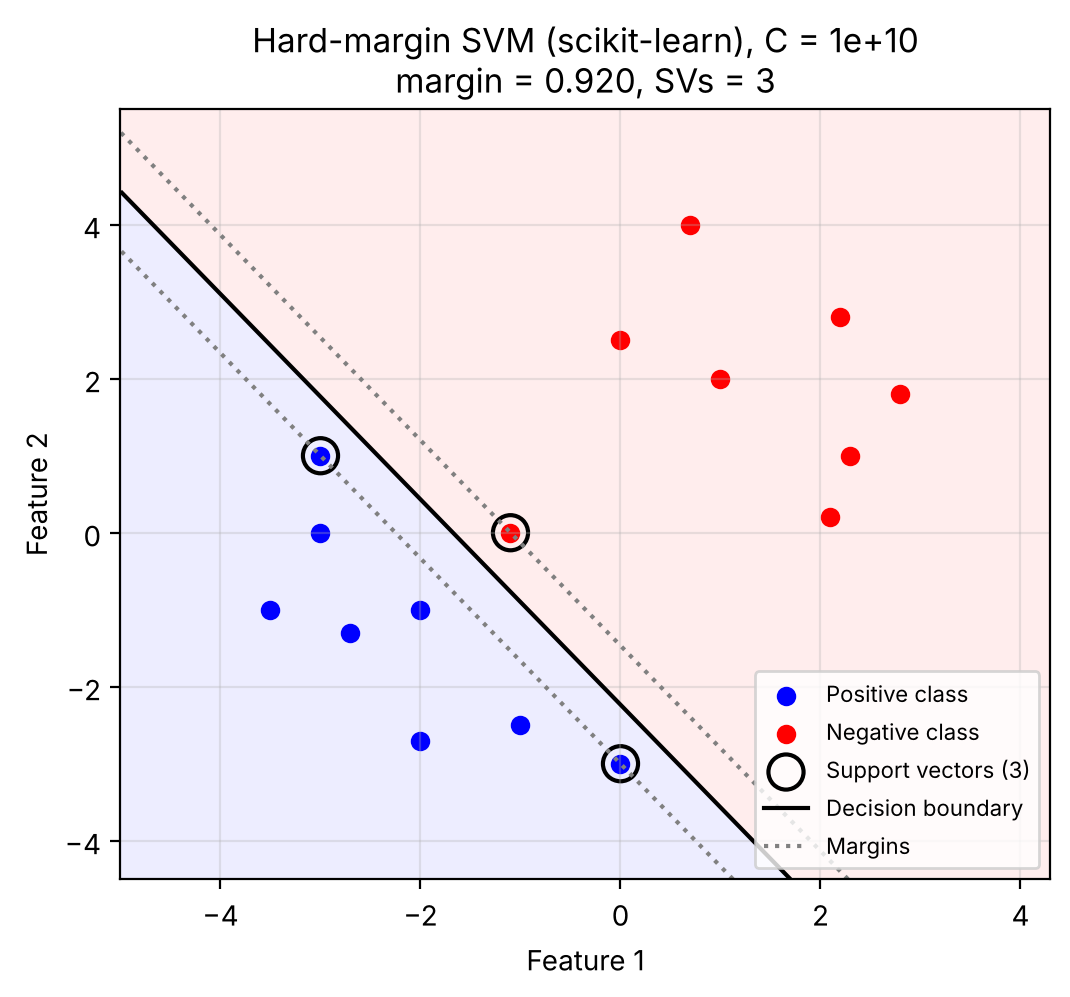


Optimal W (hard margin): [-1.73838548 -1.30378914]
Optimal b (hard margin): -2.9116528947672458
Support vectors:
 [[-1.1  0. ]
 [-3.   1. ]
 [ 0.  -3. ]]
alpha_i * y_i: [-2.36193681  1.44550532  0.91643149]
Functional margins y_i(W.x_i + b) of the SVs (should be 1): [0.9994 0.9997 0.9997]

cvxpy hard margin:  W = [-1.7391 -1.3043]  b = -2.913  SVs: [[-3.0, 1.0], [0.0, -3.0], [-1.1, 0.0]]


In [7]:
# Task 3 (hard margin)
# scikit-learn has no separate hard-margin option. A hard margin is the limit C -> infinity,
# so a very large C is used, which makes any slack prohibitively expensive.
C_hard = 1e10
hard_sk = sklearn_svm(X, y, C_hard, "Hard-margin SVM")

clf_hard = SVC(kernel='linear', C=C_hard).fit(X, y)
print("\nOptimal W (hard margin):", clf_hard.coef_[0])
print("Optimal b (hard margin):", clf_hard.intercept_[0])
print("Support vectors:\n", clf_hard.support_vectors_)
print("alpha_i * y_i:", clf_hard.dual_coef_[0])
print("Functional margins y_i(W.x_i + b) of the SVs (should be 1):",
      np.round(y[clf_hard.support_] * clf_hard.decision_function(X[clf_hard.support_]), 4))

# Compare with the cvxpy hard_margin result
W_cvx, b_cvx, a_cvx, sv_cvx = hard_margin_results(X, y)
print("\ncvxpy hard margin:  W =", np.round(W_cvx, 4), " b =", round(b_cvx, 4), " SVs:", X[sv_cvx].tolist())

**Task 3 – soft vs hard margin from a scikit-learn perspective**

* **Same model, one interface.** In scikit-learn both are `SVC(kernel='linear', C=...)`. The soft margin is any finite `C`, and the **hard margin is simply a very large `C`** (here 10¹⁰). There is no hard-margin switch, because the hard margin is the limit $C \to \infty$. If the data were not separable, a "hard-margin" SVC would still return an answer (with huge α), whereas the cvxpy hard-margin problem would be infeasible.
* **Parameter extraction.** `coef_` gives **W** and `intercept_` gives **b**. These are only available for a linear kernel; for other kernels the weights are never formed explicitly. `support_vectors_` / `support_` give the support vectors, and `dual_coef_` gives $\alpha_i y_i$ for each support vector only.
* **Agreement with cvxpy.** For every C, the scikit-learn W, b, number of support vectors and margin match the Task 2 cvxpy results up to small solver tolerances (e.g. W ≈ (−1.738, −1.304), b ≈ −2.912 for the hard margin vs (−1.739, −1.304), −2.913). scikit-learn uses the specialised SMO solver (libsvm), which stops at a tolerance of 10⁻³, so the last digits differ slightly. The one visible difference is **b at C = 0.001** (sklearn 0.004 vs cvxpy −0.010). There, every point has α = C and none lies exactly on the margin, so b is not uniquely determined, and each solver picks a different value in the allowed range. W is the same.
* **Soft-margin trend.** This is the same as in Task 2. Small C gives a very wide margin, many support vectors and one misclassified point. Large C gives a narrow margin, 3 support vectors and perfect separation. From C = 100 onwards the soft margin is identical to the hard margin, because no slack is needed.
* **Practical difference.** scikit-learn is far less code: no need to write the optimisation problem, the constraints or the dual extraction. It also scales to large datasets and non-linear kernels. cvxpy is more transparent and shows the optimisation problem explicitly, which is useful for learning and for checking the theory (e.g. the hand calculation in Task 1).